In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import shap
from sklearn.metrics import (classification_report, accuracy_score,
                            confusion_matrix, roc_auc_score, roc_curve)
sns.set_style('darkgrid')
print('Libraries installed!')

Libraries installed!


In [5]:
X_train = np.load('../data/X_train.npy')
X_test = np.load('../data/X_test_transformed.npy')
y_train = np.load('../data/y_train.npy')
y_test = np.load('../data/y_test.npy')

with open('../models/random_forest.pkl', 'rb') as f:
    rf_model = pickle.load(f)
with open('../models/xgboost.pkl', 'rb') as f:
    xgb_model = pickle.load(f)
with open('../models/ensemble.pkl', 'rb') as f:
    ensemble = pickle.load(f)
print('All models are loaded :)')

All models are loaded :)


In [7]:
models = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'Ensemble': ensemble
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    print(f'\n{'-' * 40}')
    print(f'  {name}')
    print(f'{'-' * 40}')
    print(classification_report(y_test, y_pred,
          target_names=['Legitimate', 'Phishing']))


----------------------------------------
  Random Forest
----------------------------------------
              precision    recall  f1-score   support

  Legitimate       0.96      0.95      0.95      1143
    Phishing       0.95      0.96      0.95      1143

    accuracy                           0.95      2286
   macro avg       0.95      0.95      0.95      2286
weighted avg       0.95      0.95      0.95      2286


----------------------------------------
  XGBoost
----------------------------------------
              precision    recall  f1-score   support

  Legitimate       0.97      0.96      0.96      1143
    Phishing       0.96      0.97      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286


----------------------------------------
  Ensemble
----------------------------------------
              precision    recall  f1-score   support

  Leg

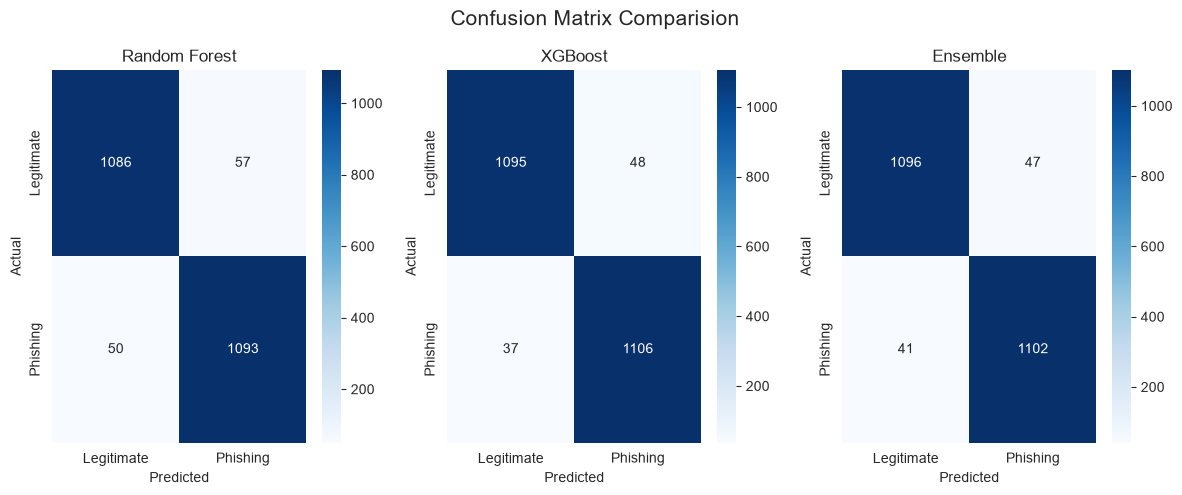

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Legitimate', 'Phishing'],
                yticklabels=['Legitimate', 'Phishing'])
    ax.set_title(f'{name}')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.suptitle('Confusion Matrix Comparision', fontsize = 15)
plt.tight_layout()
plt.savefig('../results/confusion_matrix.png')
plt.show()

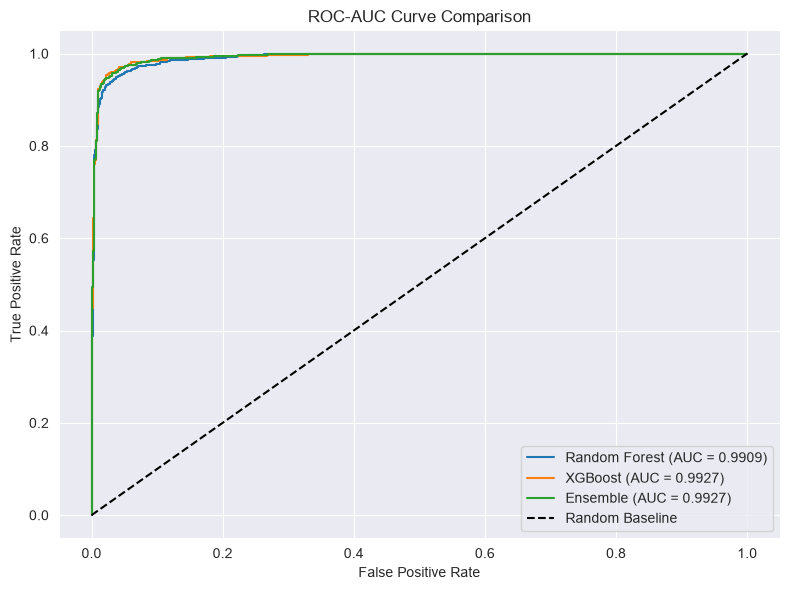

In [13]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:,1])
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0,1], [0,1], 'k--', label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve Comparison')
plt.legend()
plt.tight_layout()
plt.savefig('../results/roc_curve.png')
plt.show()

c:\Project\Phish-Print\Phish-Print\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Project\Phish-Print\Phish-Print\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SelectKBest from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Project\Phish-Print\Phish-Print\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.8.0 when using versio

Total selected features: 50
First 5: ['length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens']


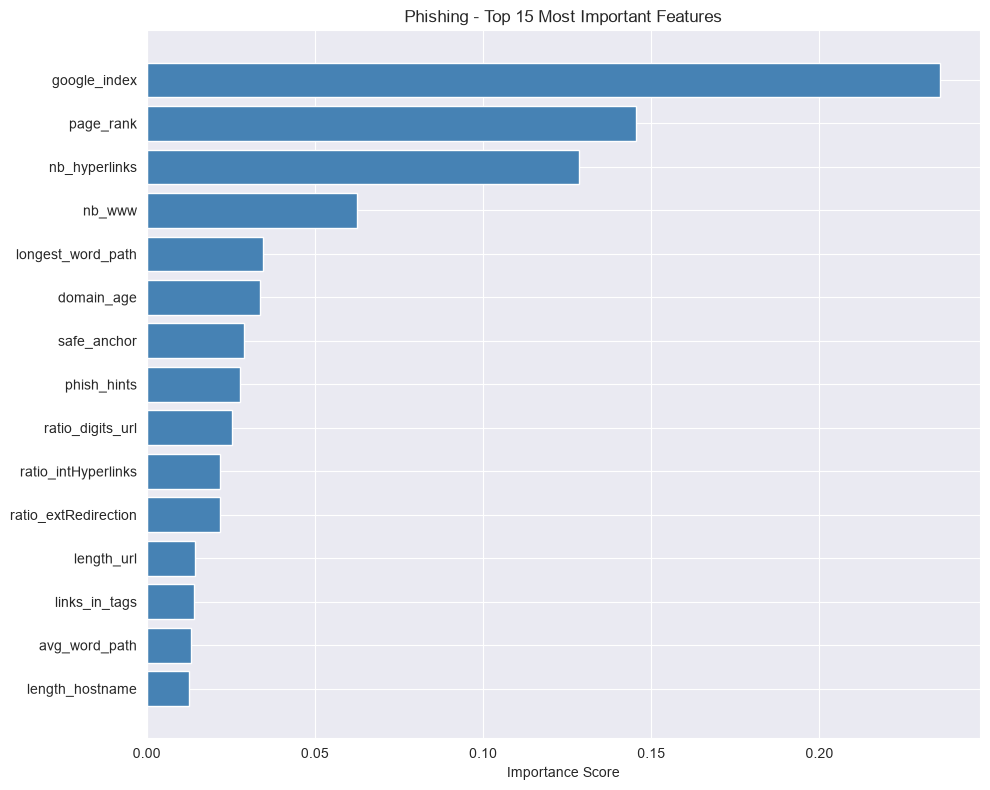

In [19]:
with open('../models/feature_pipeline.pkl', 'rb') as f:
    feature_pipeline = pickle.load(f)
import pandas as pd
df = pd.read_csv('../data/dataset.csv', index_col=0)
X = df.drop('status', axis=1)

selected_mask = feature_pipeline.named_steps['selector'].get_support()
selected_feature_names = X.columns[selected_mask].tolist()
print(f"Total selected features: {len(selected_feature_names)}")
print(f"First 5: {selected_feature_names[:5]}")

importances = rf_model.feature_importances_
indices = np.argsort(importances)[-15:]

plt.figure(figsize=(10, 8))
plt.barh(range(15), importances[indices], color='steelblue')
plt.yticks(range(15), [selected_feature_names[i] for i in indices])
plt.xlabel('Importance Score')
plt.title('Phishing - Top 15 Most Important Features')
plt.tight_layout()
plt.savefig('../results/feature_importance.png')
plt.show()

SHAP model under work!


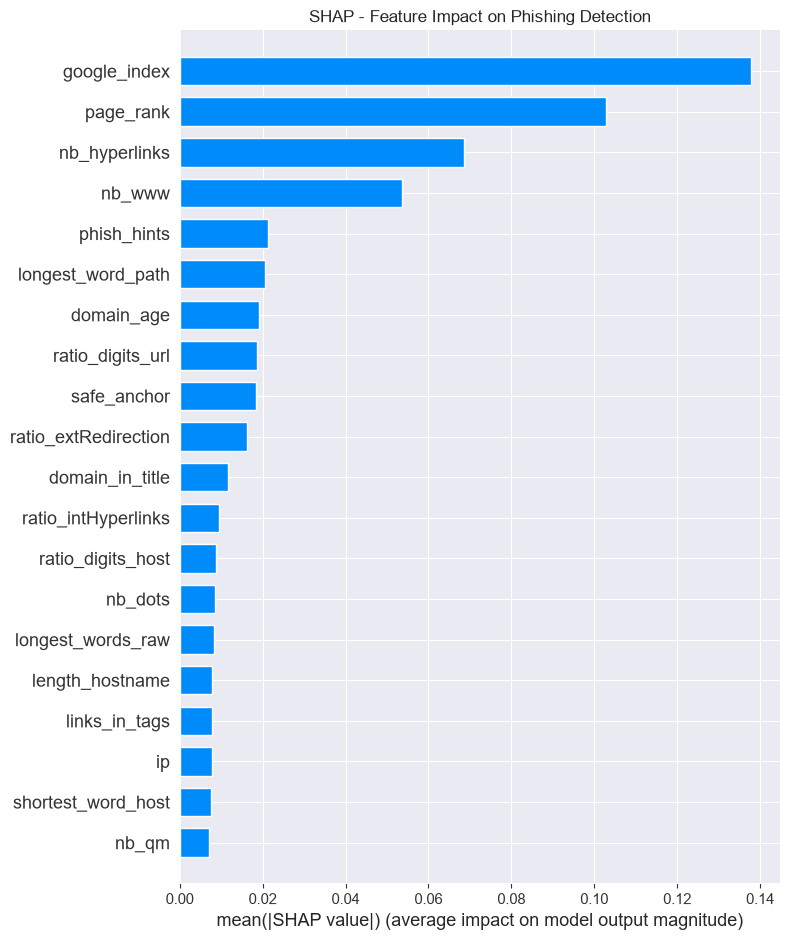

SHAP plot saved!


In [21]:
print('SHAP model under work!')
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test[:100])

plt.figure()
shap.summary_plot(shap_values[:,:,1], X_test[:100],
                  feature_names=selected_feature_names,
                  plot_type='bar',
                  show=False)
plt.title('SHAP - Feature Impact on Phishing Detection')
plt.tight_layout()
plt.tight_layout()
plt.savefig('../results/shap_summary.png')
plt.show()
print('SHAP plot saved!')

In [28]:
shap_mean = np.abs(shap_values[:,:,1]).mean(axis=0)
shap_df = pd.DataFrame({
    'feature': selected_feature_names,
    'shap_value': shap_mean
}).sort_values('shap_value', ascending=False).reset_index(drop=True).head(5)

feature_explanations = {
    'google_index': 'Phishing sites are rarely indexed by Google',
    'page_rank': 'Phishing domains have low or no page rank',
    'nb_hyperlinks': 'Phishing pages contain unusually many hyperlinks',
    'nb_www': 'Multiple www occurrences indicate fake legitimacy',
    'phish_hints': 'URL contains known phishing keywords',
    'domain_age': 'Phishing domains are newly registered',
    'ip': 'IP address used as domain is a phishing indicator'
}
print("=" * 55)
print("  PHISHPRINT - SHAP EXPLAINABILITY SUMMARY")
print("=" * 55)
print(f"\nTop 5 features driving phishing detection:\n")

for i, row in shap_df.iterrows():
    print(f"  {i+1}. {row['feature']:<25} impact: {row['shap_value']:.4f}")

print(f"""
Key Insights:
- '{shap_df.iloc[0]['feature']}' is the strongest signal
  → Phishing sites are rarely indexed by Google
- '{shap_df.iloc[1]['feature']}' is the second strongest
  → Phishing domains have low/no page rank
- '{shap_df.iloc[2]['feature']}' ranks third
  → Phishing pages contain unusually many hyperlinks
""")
print("=" * 55)

  PHISHPRINT - SHAP EXPLAINABILITY SUMMARY

Top 5 features driving phishing detection:

  1. google_index              impact: 0.1379
  2. page_rank                 impact: 0.1029
  3. nb_hyperlinks             impact: 0.0685
  4. nb_www                    impact: 0.0537
  5. phish_hints               impact: 0.0213

Key Insights:
- 'google_index' is the strongest signal
  → Phishing sites are rarely indexed by Google
- 'page_rank' is the second strongest
  → Phishing domains have low/no page rank
- 'nb_hyperlinks' ranks third
  → Phishing pages contain unusually many hyperlinks

